In [1]:
!nvidia-smi

Sat Nov 21 11:38:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!git clone https://github.com/suminilago/ICV-FMB-Fusion.git /content/ICV-FMB-Fusion
%cd /content/ICV-FMB-Fusion
%pip install -q -r requirements.txt
!mkdir -p data/FMB_raw
!cp /content/drive/MyDrive/ICV_FMB/data/train.zip /content/drive/MyDrive/ICV_FMB/data/test.zip data/FMB_raw/
!cd data/FMB_raw && unzip -q -o train.zip && unzip -q -o test.zip
!python tools/prepare_fmb.py --raw data/FMB_raw --out data/FMB_prepared

Cloning into '/content/ICV-FMB-Fusion'...
remote: Enumerating objects: 178, done.
remote: Counting objects: 100% (178/178), done.
remote: Compressing objects: 100% (162/162), done.
remote: Total 178 (delta 68), reused 35 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (178/178), 10.85 MiB | 13.53 MiB/s, done.
Resolving deltas: 100% (68/68), done.
/content/ICV-FMB-Fusion
cp: cannot stat '/content/drive/MyDrive/ICV_FMB/data/train.zip': No such file or directory
cp: cannot stat '/content/drive/MyDrive/ICV_FMB/data/test.zip': No such file or directory
unzip:  cannot find or open train.zip, train.zip.zip or train.zip.ZIP.
{'train': 0, 'test': 0}
!! could not detect the layout. folders seen (path: #images):
edit RGB_KEYS / IR_KEYS / LAB_KEYS in this script (or ask the instructor)


In [4]:
# 2) 데이터 직접 다운로드 (저자 공개 Google Drive, 재배포 없음) -- 실패하면 README 의 '다운로드 실패 시' 참고
!python tools/download_fmb.py --out data/FMB_raw

Retrieving folder contents
Processing file 1AamLVgMG5JCkhUOZi-xKTymZXCNklnaq test.zip
Processing file 1nk2R2yZ05SDe2lDpsk2D5RAngMBPUPsB train.zip
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1AamLVgMG5JCkhUOZi-xKTymZXCNklnaq
From (redirected): https://drive.google.com/uc?id=1AamLVgMG5JCkhUOZi-xKTymZXCNklnaq&confirm=t&uuid=c1e97f56-df13-4c32-b103-84f77a559eb4
To: /content/ICV-FMB-Fusion/data/FMB_raw/test.zip
100% 216M/216M [00:04<00:00, 44.6MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1nk2R2yZ05SDe2lDpsk2D5RAngMBPUPsB
From (redirected): https://drive.google.com/uc?id=1nk2R2yZ05SDe2lDpsk2D5RAngMBPUPsB&confirm=t&uuid=3e221699-c851-4d26-a063-ac7c40e8c66c
To: /content/ICV-FMB-Fusion/data/FMB_raw/train.zip
100% 914M/914M [00:11<00:00, 81.6MB/s]
Download completed
done -> data/FMB_raw (next: python tools/prepare_fmb.py --raw data/FMB_raw )


In [5]:
# 3) 분할 인덱스 생성 (train 1000 / val 220 / test 280). 출력되는 label values 를 확인!
!python tools/prepare_fmb.py --raw data/FMB_raw --out data/FMB_prepared
!ls data/FMB_prepared

{'train': 1220, 'test': 280}
label values (60 train images): [(0, 653435), (1, 3659532), (2, 454577), (3, 3719931), (4, 17998), (5, 68544), (6, 7523632), (7, 10485133), (8, 89218), (9, 1289593), (10, 302081), (11, 96007), (12, 10919), (14, 429400)]
meta: {'dataset': 'FMB', 'num_classes': 14, 'ignore': 255, 'label_shift': 1, 'aux_channels': 3} -> FMB: 0=unlabeled, 1..14 = classes (label_shift 1 is the default); if your values differ, change --label_shift
index_test.json  index_train.json  index_val.json  meta.json


# 1. B0 융합 비교 (384 x 512, 30 epoch, seed0)

## 1-1. Concat (concat -> 1x1 conv)

In [ ]:
!python -c "from fusion_seg.fusion import FUSIONS; print(list(FUSIONS))"

['sum', 'concat']


In [ ]:
!python train.py \
  --data_root data/FMB_prepared \
  --fusion concat \
  --backbone nvidia/mit-b0 \
  --epochs 30 \
  --seed 0 \
  --out /content/drive/MyDrive/ICV_FMB/runs/fmb_concat


config.json: 100% 70.0k/70.0k [00:00<00:00, 75.5MB/s]

pytorch_model.bin: downloading bytes:  68% 9.75M/14.4M [00:01<00:00, 9.47MB/s,  203kB/s  ]
pytorch_model.bin: downloading bytes: 100% 13.5M/13.5M [00:01<00:00, 8.43MB/s, 1.29MB/s  ]
pytorch_model.bin: reconstructing file: 100% 14.4M/14.4M [00:01<00:00, 8.99MB/s, 1.38MB/s  ]
Loading weights: 100% 192/192 [00:00<00:00, 25634.45it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b0
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100% 192/192 [00:00<00:00, 26775.71it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b0
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNE

In [ ]:
!ls -lh /content/drive/MyDrive/ICV_FMB/runs/fmb_concat

total 111M
-rw------- 1 root root  332 Nov 17 15:37 args.json
-rw------- 1 root root  28M Nov 17 16:14 best.pth
-rw------- 1 root root  84M Nov 17 16:17 last.pth
-rw------- 1 root root 3.0K Nov 17 16:17 log.jsonl


## 1-2. Adaptive (채널별 RGB/IR 가중치)

In [ ]:
!python -c "from fusion_seg.fusion import FUSIONS; print(list(FUSIONS))"

['sum', 'concat', 'adaptive']


In [ ]:
!cp fusion_seg/fusion.py /content/drive/MyDrive/ICV_FMB/fusion_adaptive.py

!python train.py \
  --data_root data/FMB_prepared \
  --fusion adaptive \
  --backbone nvidia/mit-b0 \
  --epochs 30 \
  --seed 0 \
  --out /content/drive/MyDrive/ICV_FMB/runs/fmb_adaptive

Loading weights: 100% 192/192 [00:00<00:00, 27072.76it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b0
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100% 192/192 [00:00<00:00, 21058.17it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b0
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
params: 7.23 M
{"epoch": 0, "loss": 1.289359518289566, "val_mIoU": 28.653505025575537, "min": 1.2779330412546794}
{"epoch": 1, "loss": 0.4125285680294037, "val_mIoU": 35.21194723521376, "min": 2.61523756980896}
{"epoch": 2

In [ ]:
!ls -lh /content/drive/MyDrive/ICV_FMB/runs/fmb_adaptive

total 111M
-rw------- 1 root root  336 Nov 17 16:23 args.json
-rw------- 1 root root  28M Nov 17 17:03 best.pth
-rw------- 1 root root  84M Nov 17 17:04 last.pth
-rw------- 1 root root 3.0K Nov 17 17:04 log.jsonl


## 1-3. Concat_res (sum + concat잔차, 0초기화)

In [ ]:
!cp /content/drive/MyDrive/ICV_FMB/fusion_concat_res.py fusion_seg/fusion.py
!python -c "from fusion_seg.fusion import FUSIONS; print(list(FUSIONS))"

['sum', 'concat', 'adaptive', 'concat_res']


In [ ]:
!python -c "from fusion_seg.fusion import FUSIONS; print(list(FUSIONS))"
!python train.py \
  --data_root data/FMB_prepared \
  --fusion concat_res \
  --epochs 30 \
  --seed 0 \
  --out /content/drive/MyDrive/ICV_FMB/runs/fmb_concat_res

['sum', 'concat', 'adaptive', 'concat_res']
config.json: 100% 70.0k/70.0k [00:00<00:00, 27.0MB/s]

pytorch_model.bin: downloading bytes:  46% 6.56M/14.4M [00:00<00:00, 12.4MB/s]
pytorch_model.bin: downloading bytes: 100% 13.5M/13.5M [00:00<00:00, 21.0MB/s, 1.32MB/s  ]
pytorch_model.bin: reconstructing file: 100% 14.4M/14.4M [00:00<00:00, 22.4MB/s, 1.41MB/s  ]
Loading weights: 100% 192/192 [00:00<00:00, 26182.86it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b0
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100% 192/192 [00:00<00:00, 24751.24it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b0
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   

## 1-4. Early (입력 단계 융합, 인코더 1개)

In [ ]:
!python train.py \
  --data_root data/FMB_prepared \
  --fusion early \
  --epochs 30 \
  --seed 0 \
  --out /content/drive/MyDrive/ICV_FMB/runs/fmb_early

config.json: 100% 70.0k/70.0k [00:00<00:00, 67.6MB/s]

pytorch_model.bin: downloading bytes:  18% 2.53M/14.4M [00:00<00:02, 4.28MB/s]
pytorch_model.bin: downloading bytes: 100% 13.5M/13.5M [00:00<00:00, 18.3MB/s, 1.32MB/s  ]
pytorch_model.bin: reconstructing file: 100% 14.4M/14.4M [00:00<00:00, 19.5MB/s, 1.41MB/s  ]
Loading weights: 100% 192/192 [00:00<00:00, 15069.64it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b0
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
params: 3.72 M

model.safetensors: downloading bytes:  86% 12.3M/14.3M [00:00<00:00, 23.8MB/s,  213kB/s  ]
model.safetensors: downloading bytes: 100% 13.6M/13.6M [00:00<00:00, 19.0MB/s, 1.33MB/s  ]
model.safetensors: reconstructing file: 100% 14.3M/14.3M [00:00<00:00, 20.0MB/s, 1.40MB/s  ]
{"

# 2. B2 실험 (MiT-B2, 30epoch, seed 0)

## 2-1. B2 Sum, 384x512

In [ ]:
!python train.py \
  --data_root data/FMB_prepared \
  --fusion sum \
  --backbone nvidia/mit-b2 \
  --epochs 30 \
  --seed 0 \
  --out /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum

config.json: 100% 70.0k/70.0k [00:00<00:00, 63.8MB/s]

pytorch_model.bin: downloading bytes:  94% 93.2M/99.0M [00:01<00:00, 121MB/s, 7.06MB/s  ]
pytorch_model.bin: downloading bytes: 100% 93.2M/93.2M [00:01<00:00, 65.6MB/s, 8.88MB/s  ]
pytorch_model.bin: reconstructing file: 100% 99.0M/99.0M [00:01<00:00, 69.6MB/s, 9.55MB/s  ]
Loading weights:   0% 0/364 [00:00<?, ?it/s]
Loading weights: 100% 364/364 [00:00<00:00, 9146.40it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b2
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
model.safetensors: downloading bytes:  41% 41.0M/98.9M [00:00<00:00, 106MB/s,   ???B/s  ] 

Loading weights: 100% 364/364 [00:00<00:00, 5469.14it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b2
Key               | Status 

## 2-2. B2 Sum, 480x640 (최종 모델)

In [ ]:
!python train.py \
  --data_root data/FMB_prepared \
  --fusion sum \
  --backbone nvidia/mit-b2 \
  --height 480 --width 640 \
  --epochs 30 \
  --seed 0 \
  --out /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum_480

config.json: 100% 70.0k/70.0k [00:00<00:00, 69.3MB/s]

pytorch_model.bin: downloading bytes:  82% 81.2M/99.0M [00:01<00:00, 113MB/s, 5.91MB/s  ] 
pytorch_model.bin: downloading bytes: 100% 93.2M/93.2M [00:01<00:00, 71.6MB/s, 8.93MB/s  ]
pytorch_model.bin: reconstructing file: 100% 99.0M/99.0M [00:01<00:00, 76.0MB/s, 9.56MB/s  ]
Loading weights: 100% 364/364 [00:00<00:00, 23308.09it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b2
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100% 364/364 [00:00<00:00, 25180.63it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b2
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNE

## 2-3. B2 RGB 단독, 480x640 (최종설정 기준 IR 기여 확인)

In [ ]:
!python train.py \
  --data_root data/FMB_prepared \
  --fusion rgb \
  --backbone nvidia/mit-b2 \
  --height 480 --width 640 \
  --epochs 30 \
  --seed 0 \
  --out /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_rgb_480

Loading weights: 100% 364/364 [00:00<00:00, 17186.87it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b2
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
params: 27.36 M
{"epoch": 0, "loss": 0.9153099113702774, "val_mIoU": 43.024863179743924, "min": 1.7129018624623618}
{"epoch": 1, "loss": 0.32037034583091734, "val_mIoU": 48.90366091353978, "min": 3.501498305797577}
{"epoch": 2, "loss": 0.25865150725841524, "val_mIoU": 54.71391058180048, "min": 5.3814383268356325}
{"epoch": 3, "loss": 0.2265983245372772, "val_mIoU": 56.77856050871137, "min": 7.3030805309613545}
{"epoch": 4, "loss": 0.20752633917331695, "val_mIoU": 60.51641437141419, "min": 9.171512500445049}
{"epoch": 5, "loss": 0.1915176284313202, "val_mIoU": 61.99290870152744, "min": 11.0993252714475}
{

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!ls -lh /content/drive/MyDrive/ICV_FMB/fusion_adaptive.py
!ls -lh /content/drive/MyDrive/ICV_FMB/runs/fmb_adaptive

Mounted at /content/drive
-rw------- 1 root root 1.8K Nov 17 16:23 /content/drive/MyDrive/ICV_FMB/fusion_adaptive.py
total 111M
-rw------- 1 root root  336 Nov 17 16:23 args.json
-rw------- 1 root root  28M Nov 17 17:03 best.pth
-rw------- 1 root root  84M Nov 17 17:04 last.pth
-rw------- 1 root root 3.0K Nov 17 17:04 log.jsonl


In [ ]:
%cd /content/ICV-FMB-Fusion

!python train_oversample.py \
  --data_root data/FMB_prepared \
  --fusion sum \
  --backbone nvidia/mit-b2 \
  --height 480 \
  --width 640 \
  --epochs 30 \
  --bs 8 \
  --seed 0 \
  --target_fraction 0.10 \
  --out /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum_480_oversample10

/content/ICV-FMB-Fusion
Class 12 positive images: 10
Class 12 negative images: 990
Positive sampling weight: 11.0
Expected positive fraction: 0.1
config.json: 100% 70.0k/70.0k [00:00<00:00, 72.6MB/s]

pytorch_model.bin: downloading bytes:  89% 87.9M/99.0M [00:01<00:00, 117MB/s, 6.66MB/s  ] 
pytorch_model.bin: downloading bytes: 100% 93.2M/93.2M [00:01<00:00, 68.6MB/s, 8.86MB/s  ]
pytorch_model.bin: reconstructing file: 100% 99.0M/99.0M [00:01<00:00, 72.8MB/s, 9.58MB/s  ]
Loading weights: 100% 364/364 [00:00<00:00, 18159.97it/s]
[transformers] SegformerModel LOAD REPORT from: nvidia/mit-b2
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.

model.safetensors: downloading bytes:   0% 0.00/98.9M [00:00<?, ?B/s]

Loading weights: 100% 364/364 [00:00<00:00, 16939.54it/s]
[tran

# 3. 분석

## 3-1. 학습 곡선 (Concat vs Adaptive)

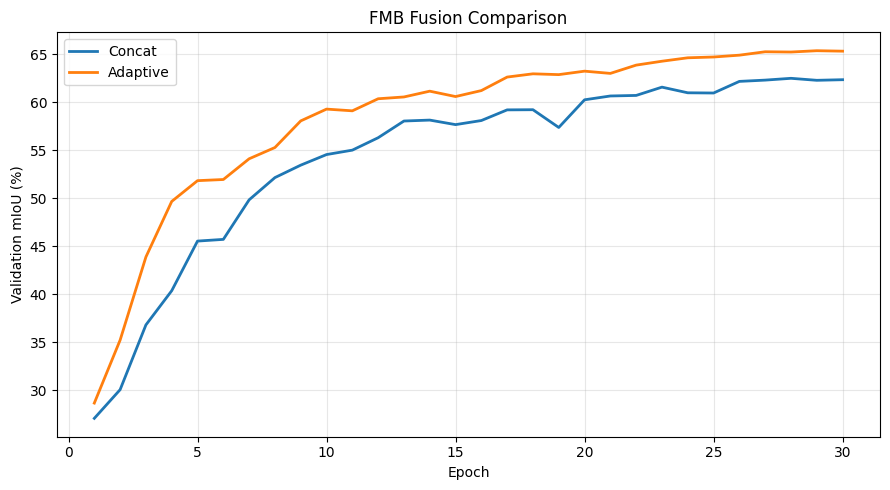

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from google.colab import files

runs_dir = Path("/content/drive/MyDrive/ICV_FMB/runs")
output = "/content/fusion_val_miou.png"

fig, ax = plt.subplots(figsize=(9, 5))
for label, folder in [("Concat", "fmb_concat"), ("Adaptive", "fmb_adaptive")]:
    log = runs_dir / folder / "log.jsonl"
    rows = [json.loads(line) for line in log.read_text().splitlines() if line.strip()]
    ax.plot(
        [row["epoch"] + 1 for row in rows],
        [row["val_mIoU"] for row in rows],
        label=label,
        linewidth=2,
    )

ax.set(title="FMB Fusion Comparison", xlabel="Epoch", ylabel="Validation mIoU (%)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(output, dpi=180)
plt.show()
files.download(output)

## 3-2. Concat/Adaptive 클래스별 IoU(val)

In [ ]:
%cd /content/ICV-FMB-Fusion
!python predict.py \
  --data_root data/FMB_prepared \
  --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_adaptive/best.pth \
  --split val \
  --out /content/val_adaptive

/content/ICV-FMB-Fusion
220 files -> /content/val_adaptive.zip


In [ ]:
%cd /content/ICV-FMB-Fusion
!python predict.py \
  --data_root data/FMB_prepared \
  --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_concat/best.pth \
  --split val \
  --out /content/val_concat

/content/ICV-FMB-Fusion
220 files -> /content/val_concat.zip


In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

root = Path("/content/ICV-FMB-Fusion/data/FMB_prepared")
samples = json.loads((root / "index_val.json").read_text())
meta = json.loads((root / "meta.json").read_text())
n_classes = meta["num_classes"]
assert len(samples) == 220, f"검증 이미지 수 확인: {len(samples)}장"

pred_dirs = {
    "Concat": Path("/content/val_concat"),
    "Adaptive": Path("/content/val_adaptive"),
}
confusion = {
    model: np.zeros((n_classes, n_classes), dtype=np.int64)
    for model in pred_dirs
}

def read_mask(path):
    with Image.open(path) as image:
        return np.array(image, dtype=np.int64)

for sample in samples:
    raw = read_mask(root / sample["label"])
    gt = raw - meta["label_shift"]
    valid = (raw != meta["ignore"]) & (gt >= 0) & (gt < n_classes)

    for model, folder in pred_dirs.items():
        pred = read_mask(folder / sample["name"])
        assert pred.ndim == 2 and pred.shape == gt.shape, (
            f"{model} {sample['name']}: 예측 크기 {pred.shape}, 정답 크기 {gt.shape}"
        )
        assert np.all((pred >= 0) & (pred < n_classes)), (
            f"{model} {sample['name']}: 예측 클래스 번호 범위 오류"
        )
        pairs = n_classes * gt[valid] + pred[valid]
        confusion[model] += np.bincount(
            pairs, minlength=n_classes**2
        ).reshape(n_classes, n_classes)

results = pd.DataFrame({"class_id": np.arange(n_classes)})
results["gt_pixels"] = confusion["Concat"].sum(axis=1)

for model, matrix in confusion.items():
    intersection = matrix.diagonal()
    union = matrix.sum(axis=1) + matrix.sum(axis=0) - intersection
    results[f"{model}_IoU_pct"] = np.divide(
        100.0 * intersection,
        union,
        out=np.full(n_classes, np.nan),
        where=union > 0,
    )

results["Adaptive_minus_Concat_pp"] = (
    results["Adaptive_IoU_pct"] - results["Concat_IoU_pct"]
)

output = Path("/content/fusion_class_iou.csv")
results.to_csv(output, index=False, float_format="%.4f")
display(results.loc[results["class_id"].isin([7, 12])].round(2))
print(f"CSV 저장 완료 → {output}")

,class_id,gt_pixels,Concat_IoU_pct,Adaptive_IoU_pct,Adaptive_minus_Concat_pp
7,7,311999,55.11,58.18,3.08
12,12,994,0.00,0.00,0.00


CSV 저장 완료 → /content/fusion_class_iou.csv


## 3-3. B2 Sum(384x512) 클래스별 IoU, 혼동, 실패 사례(val)

In [ ]:
%cd /content/ICV-FMB-Fusion
!python predict.py \
  --data_root data/FMB_prepared \
  --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum/best.pth \
  --split val \
  --out /content/val_b2_sum

/content/ICV-FMB-Fusion
220 files -> /content/val_b2_sum.zip


In [ ]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

root = Path("data/FMB_prepared")
meta = json.loads((root / "meta.json").read_text())
items = json.loads((root / "index_val.json").read_text())
NC, IGN, SHIFT = meta["num_classes"], meta["ignore"], meta["label_shift"]
NAMES = ["Road", "Sidewalk", "Building", "TrafficLight", "TrafficSign", "Vegetation", "Sky",
         "Person", "Car", "Truck", "Bus", "Motorcycle", "Bicycle", "Pole"]

def load_gt(it):
    gt = np.array(Image.open(root / it["label"])).astype(np.int64) - SHIFT
    gt[(gt < 0) | (gt >= NC)] = IGN
    return gt

def confusion(pred_dir):
    cm = np.zeros((NC, NC), np.int64)
    for it in items:
        gt = load_gt(it)
        pr = np.array(Image.open(Path(pred_dir) / it["name"])).astype(np.int64)
        m = gt != IGN
        cm += np.bincount(gt[m] * NC + pr[m], minlength=NC * NC).reshape(NC, NC)
    return cm

def iou(cm):
    tp = np.diag(cm).astype(float)
    return 100 * tp / np.maximum(cm.sum(0) + cm.sum(1) - tp, 1)

cm_b2 = confusion("/content/val_b2_sum")
iou_b2 = iou(cm_b2)
print(f"B2 Sum val mIoU (재계산): {iou_b2.mean():.2f}")

df = pd.DataFrame({"class_id": range(NC), "name": NAMES, "gt_pixels": cm_b2.sum(1)})
old1 = pd.read_csv("results/class_iou_comparison.csv")
old2 = pd.read_csv("results/fusion_class_iou.csv")
df = df.merge(old1[["Class", "RGB_IoU", "Sum_IoU"]].rename(columns={"Class": "class_id"}), on="class_id")
df = df.merge(old2[["class_id", "Concat_IoU_pct", "Adaptive_IoU_pct"]], on="class_id")
df["B2_Sum"] = iou_b2
df = df.rename(columns={"RGB_IoU": "B0_RGB", "Sum_IoU": "B0_Sum",
                        "Concat_IoU_pct": "B0_Concat", "Adaptive_IoU_pct": "B0_Adaptive"})
df["B2_minus_B0Sum"] = df["B2_Sum"] - df["B0_Sum"]
pd.set_option("display.width", 200)
display(df.round(2).sort_values("B2_minus_B0Sum", ascending=False))
df.round(4).to_csv("/content/drive/MyDrive/ICV_FMB/b2_class_iou.csv", index=False)

B2 Sum val mIoU (재계산): 72.74


,class_id,name,gt_pixels,B0_RGB,B0_Sum,B0_Concat,B0_Adaptive,B2_Sum,B2_minus_B0Sum
12,12,Bicycle,994,0.00,0.00,0.00,0.00,39.83,39.83
3,3,TrafficLight,72676,46.61,51.57,45.59,50.23,61.78,10.21
11,11,Motorcycle,48405,46.41,53.78,48.01,55.38,63.13,9.35
10,10,Bus,287777,66.69,69.40,65.86,68.54,77.05,7.65
13,13,Pole,1576838,46.62,50.17,47.16,50.96,57.29,7.12
7,7,Person,311999,38.90,58.17,55.11,58.18,65.14,6.97
1,1,Sidewalk,2098203,48.41,51.46,47.41,51.61,57.03,5.57
4,4,TrafficSign,226116,70.39,70.00,65.79,70.33,75.57,5.57
8,8,Car,5477753,82.06,85.17,83.60,85.33,88.53,3.36
2,2,Building,16543642,85.79,87.59,86.94,87.61,89.72,2.13


In [ ]:
rows = []
for c in np.argsort(iou_b2)[:6]:
    r = cm_b2[c].astype(float); total = r.sum(); r[c] = 0
    top = np.argsort(r)[::-1][:3]
    rows.append({"class": f"{c} {NAMES[c]}", "IoU": round(iou_b2[c], 2),
                 **{f"오답{k+1}": f"{NAMES[t]} {100 * r[t] / max(total, 1):.1f}%" for k, t in enumerate(top)}})
display(pd.DataFrame(rows))

,class,IoU,오답1,오답2,오답3
0,12 Bicycle,39.83,Car 26.3%,Sky 17.2%,Sidewalk 6.6%
1,1 Sidewalk,57.03,Road 25.7%,Vegetation 3.5%,Car 1.1%
2,13 Pole,57.29,Vegetation 15.0%,Building 9.6%,Sky 7.0%
3,3 TrafficLight,61.78,Vegetation 11.9%,Building 8.2%,Sky 2.8%
4,11 Motorcycle,63.13,Car 15.4%,Person 3.8%,Bus 3.6%
5,7 Person,65.14,Car 7.5%,Vegetation 6.4%,Building 3.4%


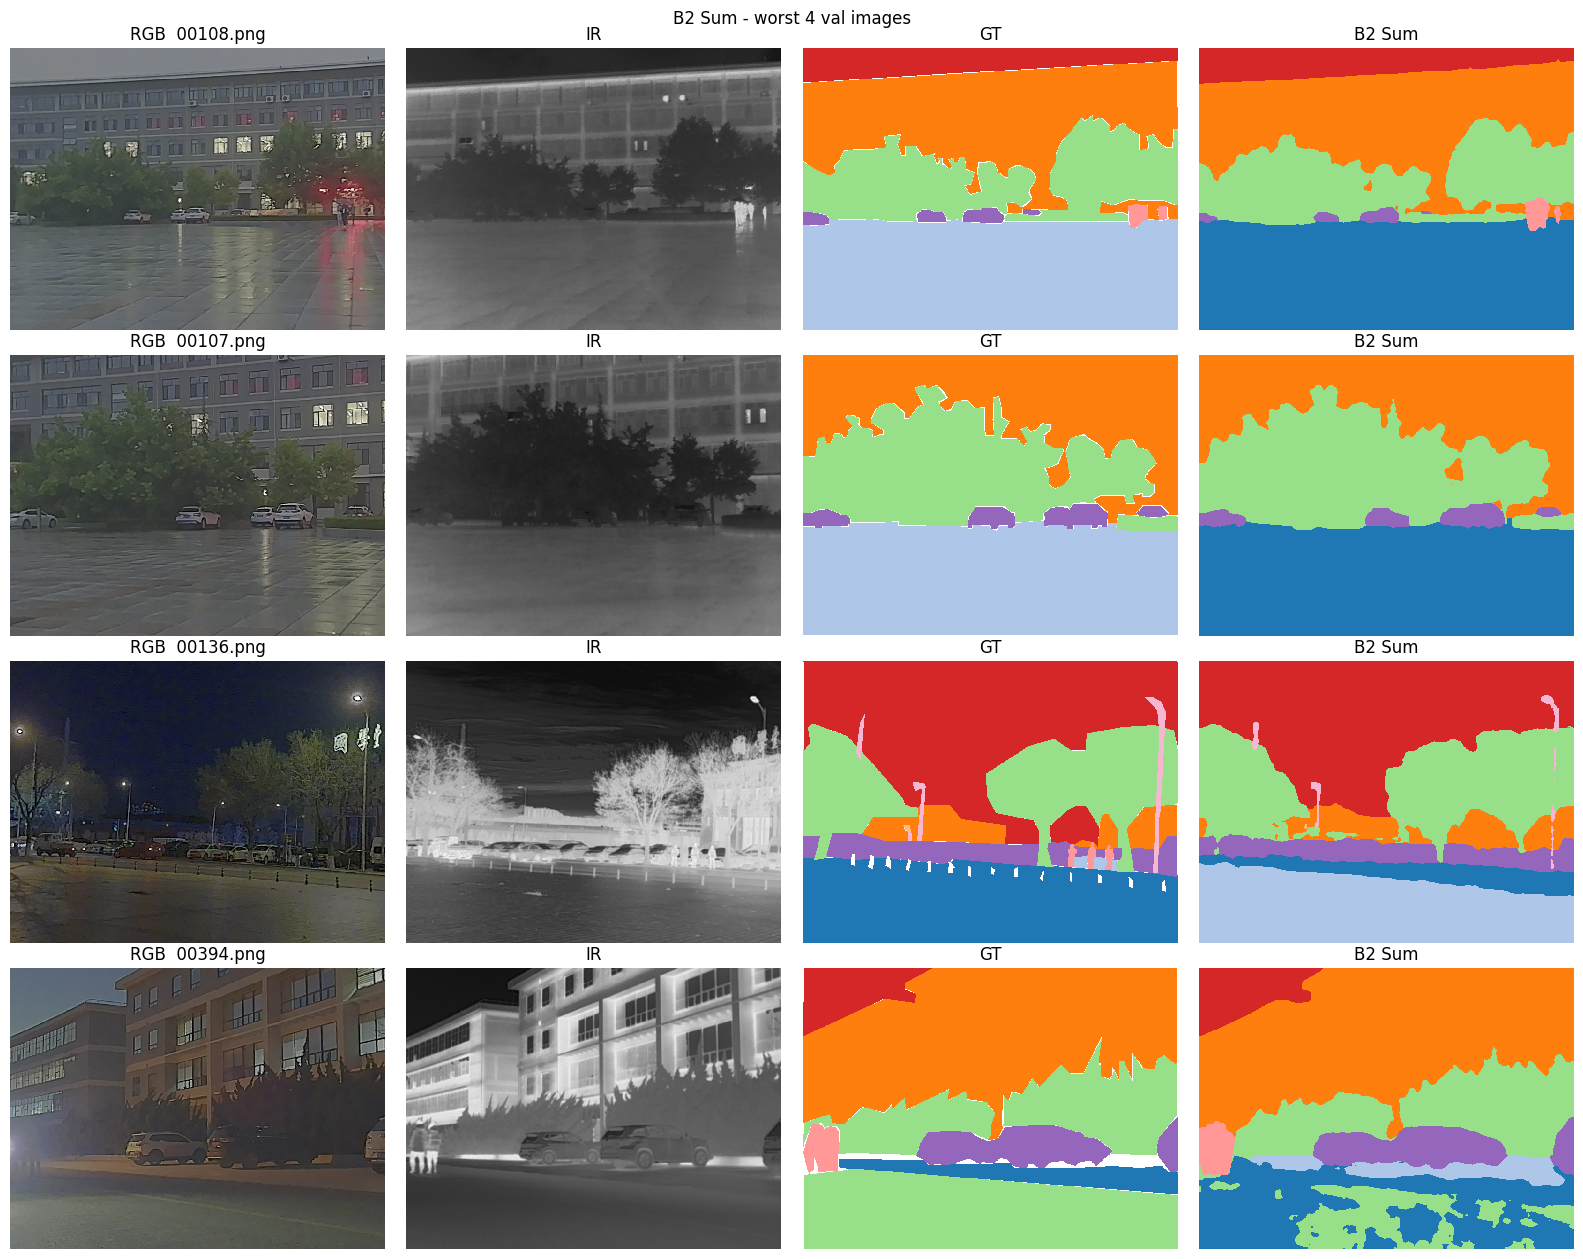

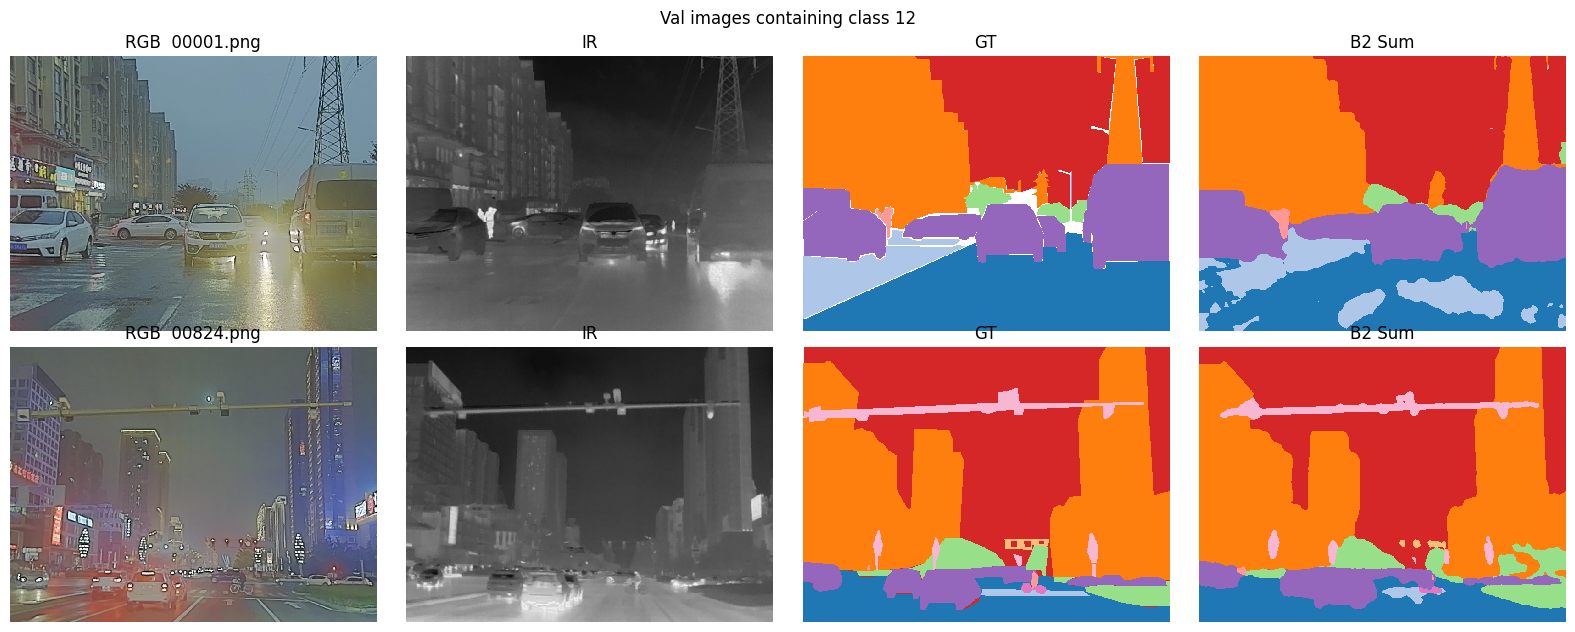

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

cmap = ListedColormap(plt.cm.tab20(np.linspace(0, 1, 20))[:NC])

def show(names, title):
    fig, axes = plt.subplots(len(names), 4, figsize=(16, 3.2 * len(names)))
    for row, name in zip(np.atleast_2d(axes), names):
        it = next(i for i in items if i["name"] == name)
        gt = load_gt(it).astype(float); gt[gt == IGN] = np.nan
        pr = np.array(Image.open(f"/content/val_b2_sum/{name}"))
        for ax, img, t in zip(row,
                              [Image.open(root / it["rgb"]), Image.open(root / it["aux"]), gt, pr],
                              ["RGB", "IR", "GT", "B2 Sum"]):
            ax.imshow(img, cmap=cmap if t in ("GT", "B2 Sum") else None, vmin=0, vmax=NC - 1, interpolation="nearest")
            ax.set_title(f"{t}  {name}" if t == "RGB" else t); ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

acc = []
for it in items:
    gt = load_gt(it); pr = np.array(Image.open(f"/content/val_b2_sum/{it['name']}")); m = gt != IGN
    acc.append(((pr[m] == gt[m]).mean(), it["name"]))
show([n for _, n in sorted(acc)[:4]], "B2 Sum - worst 4 val images")

c12 = [it["name"] for it in items if (load_gt(it) == 12).any()]
show(c12, "Val images containing class 12")

,실험,best val mIoU,best epoch (1부터),기록된 epoch 수,마지막 val
0,B0 Concat,62.47,28,30,62.33
1,B0 Adaptive,65.35,29,30,65.30
2,B0 Concat_res,64.95,27,30,64.89
3,B0 Early,62.19,30,30,62.19
4,B2 Sum 384,72.74,29,30,72.38
5,B2 Sum 480,73.65,30,30,73.65
6,B2 RGB 480,70.99,30,30,70.99


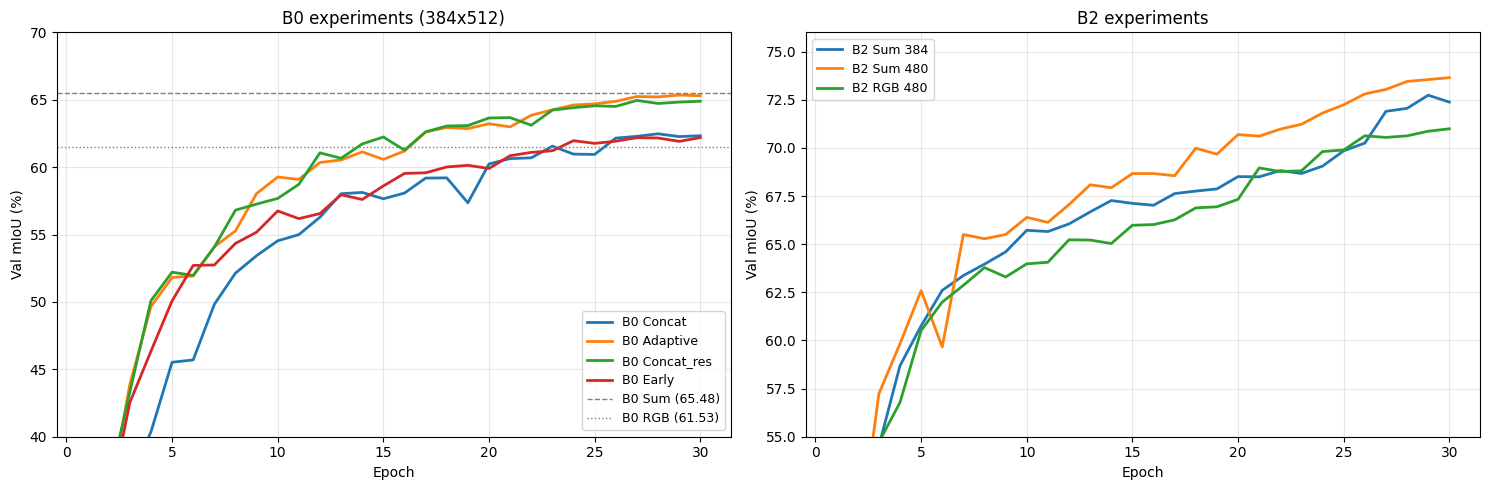

In [ ]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RUNS = Path("/content/drive/MyDrive/ICV_FMB/runs")
OUT = Path("/content/drive/MyDrive/ICV_FMB/analysis"); OUT.mkdir(parents=True, exist_ok=True)
EXPS = [("B0 Concat", "fmb_concat"), ("B0 Adaptive", "fmb_adaptive"),
        ("B0 Concat_res", "fmb_concat_res"), ("B0 Early", "fmb_early"),
        ("B2 Sum 384", "fmb_b2_sum"), ("B2 Sum 480", "fmb_b2_sum_480"), ("B2 RGB 480", "fmb_b2_rgb_480")]

rows, logs = [], {}
for label, folder in EXPS:
    recs = [json.loads(l) for l in (RUNS / folder / "log.jsonl").read_text().splitlines() if l.strip()]
    logs[label] = recs
    best = max(recs, key=lambda r: r["val_mIoU"])
    rows.append({"실험": label, "best val mIoU": round(best["val_mIoU"], 2),
                 "best epoch (1부터)": best["epoch"] + 1, "기록된 epoch 수": len(recs),
                 "마지막 val": round(recs[-1]["val_mIoU"], 2)})
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv(OUT / "run_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for label, recs in logs.items():
    ax = axes[1] if label.startswith("B2") else axes[0]
    ax.plot([r["epoch"] + 1 for r in recs], [r["val_mIoU"] for r in recs], label=label, lw=2)
# 팀원 Drive에 있는 B0 결과는 최종 값만 점선으로 표시
axes[0].axhline(65.48, ls="--", c="gray", lw=1, label="B0 Sum (65.48)")
axes[0].axhline(61.53, ls=":", c="gray", lw=1, label="B0 RGB (61.53)")
axes[0].set(title="B0 experiments (384x512)", xlabel="Epoch", ylabel="Val mIoU (%)", ylim=(40, 70))
axes[1].set(title="B2 experiments", xlabel="Epoch", ylabel="Val mIoU (%)", ylim=(55, 76))
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "learning_curves.png", dpi=180); plt.show()

In [8]:
%cd /content/ICV-FMB-Fusion
!python predict.py --data_root data/FMB_prepared --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum_480/best.pth --split val --out /content/val_b2_sum_480
!python predict.py --data_root data/FMB_prepared --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_rgb_480/best.pth --split val --out /content/val_b2_rgb_480
!python predict.py --data_root data/FMB_prepared --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum_480/best.pth --split val --out /content/val_b2_sum_480_flip --flip

/content/ICV-FMB-Fusion
220 files -> /content/val_b2_sum_480.zip
220 files -> /content/val_b2_rgb_480.zip
220 files -> /content/val_b2_sum_480_flip.zip


In [7]:
!ls -la /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_rgb_480/
!ls /content/drive/MyDrive/ICV_FMB/runs/

ls: cannot access '/content/drive/MyDrive/ICV_FMB/runs/fmb_b2_rgb_480/': No such file or directory
fmb_b2_sum_480	fmb_b2_sum_480_oversample10


,모델,val mIoU
0,B2 RGB 480,70.99
1,B2 Sum 480,73.65
2,B2 Sum 480 +flip,73.63


,class_id,name,gt_pixels,B2_RGB_480,B2_Sum_480,IR_gain
7,7,Person,311999,48.36,67.16,18.79
12,12,Bicycle,994,38.80,46.60,7.81
11,11,Motorcycle,48405,61.11,64.15,3.04
13,13,Pole,1576838,58.06,60.72,2.66
8,8,Car,5477753,86.68,88.95,2.27
3,3,TrafficLight,72676,61.48,63.10,1.63
1,1,Sidewalk,2098203,55.85,57.04,1.19
2,2,Building,16543642,88.69,89.83,1.13
5,5,Vegetation,24954772,90.44,91.12,0.68
6,6,Sky,38214184,95.90,96.54,0.63


,밝기 그룹,이미지 수,평균 밝기 범위(0-255),B2 RGB 480,B2 Sum 480,B2 Sum 480 +flip,IR 기여 (Sum-RGB)
0,어두움,73,39~98,61.91,66.55,66.87,4.64
1,중간,73,98~149,73.06,75.86,75.67,2.80
2,밝음,74,149~162,73.94,74.83,75.28,0.89


,name,어두움_RGB,어두움_Sum,IR_gain_dark
7,Person,42.32,65.82,23.50
9,Truck,41.94,49.68,7.74
3,TrafficLight,28.46,34.30,5.84
11,Motorcycle,28.00,33.22,5.22
10,Bus,57.88,62.88,5.00
8,Car,84.47,88.46,3.99
13,Pole,58.54,62.23,3.69
2,Building,88.39,89.81,1.42
1,Sidewalk,34.75,36.16,1.41
4,TrafficSign,73.61,74.65,1.03


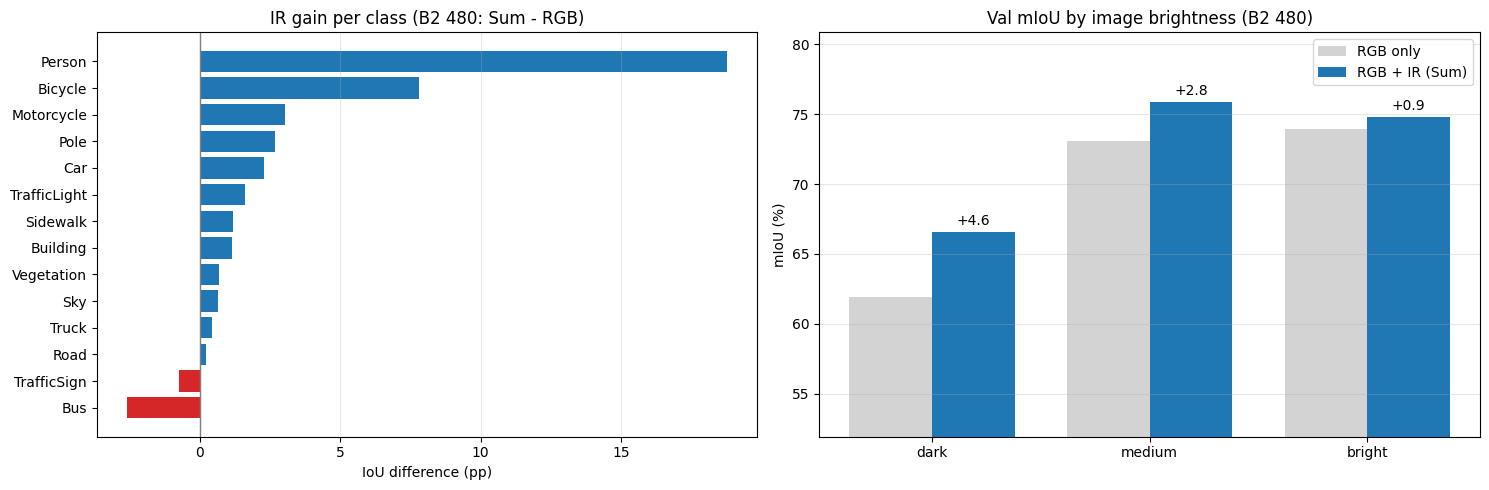

In [ ]:
import numpy as np
from PIL import Image

root = Path("data/FMB_prepared")
meta = json.loads((root / "meta.json").read_text())
items = json.loads((root / "index_val.json").read_text())
NC, IGN, SHIFT = meta["num_classes"], meta["ignore"], meta["label_shift"]
NAMES = ["Road", "Sidewalk", "Building", "TrafficLight", "TrafficSign", "Vegetation", "Sky",
         "Person", "Car", "Truck", "Bus", "Motorcycle", "Bicycle", "Pole"]
MODELS = {"B2 RGB 480": "/content/val_b2_rgb_480",
          "B2 Sum 480": "/content/val_b2_sum_480",
          "B2 Sum 480 +flip": "/content/val_b2_sum_480_flip"}

def load_gt(it):
    gt = np.array(Image.open(root / it["label"])).astype(np.int64) - SHIFT
    gt[(gt < 0) | (gt >= NC)] = IGN
    return gt

def miou(cm):
    tp = np.diag(cm).astype(float)
    union = cm.sum(0) + cm.sum(1) - tp
    iou = np.where(union > 0, tp / np.maximum(union, 1), np.nan) * 100
    present = cm.sum(1) > 0
    return np.nanmean(np.where(present, iou, np.nan)), np.where(present, iou, np.nan)

# 이미지별 혼동행렬 + RGB 평균 밝기
cms = {k: {} for k in MODELS}
bright = {}
for it in items:
    n = it["name"]
    gt = load_gt(it); m = gt != IGN; g = gt[m]
    bright[n] = float(np.asarray(Image.open(root / it["rgb"]).convert("L"), dtype=np.float32).mean())
    for k, d in MODELS.items():
        p = np.array(Image.open(f"{d}/{n}")).astype(np.int64)[m]
        cms[k][n] = np.bincount(g * NC + p, minlength=NC * NC).reshape(NC, NC)
names = [it["name"] for it in items]
total = {k: sum(cms[k][n] for n in names) for k in MODELS}

# ⑥ 전체 mIoU (B2 Sum 480 이 73.65 근처면 정상)
overall = pd.DataFrame([{"모델": k, "val mIoU": round(miou(total[k])[0], 2)} for k in MODELS])
display(overall); overall.to_csv(OUT / "val_overall_tta.csv", index=False)

# ③ 클래스별: IR 기여
_, iou_rgb = miou(total["B2 RGB 480"]); _, iou_sum = miou(total["B2 Sum 480"])
cls = pd.DataFrame({"class_id": range(NC), "name": NAMES, "gt_pixels": total["B2 Sum 480"].sum(1),
                    "B2_RGB_480": iou_rgb, "B2_Sum_480": iou_sum})
cls["IR_gain"] = cls["B2_Sum_480"] - cls["B2_RGB_480"]
cls = cls.sort_values("IR_gain", ascending=False)
display(cls.round(2)); cls.round(4).to_csv(OUT / "class_iou_rgb_vs_sum_480.csv", index=False)

# ④ 밝기별: 평균 밝기 기준 3등분
order = sorted(names, key=lambda n: bright[n]); k3 = len(order) // 3
groups = {"어두움": order[:k3], "중간": order[k3:2 * k3], "밝음": order[2 * k3:]}
grows = []
for gname, ns in groups.items():
    r = {"밝기 그룹": gname, "이미지 수": len(ns), "평균 밝기 범위(0-255)": f"{bright[ns[0]]:.0f}~{bright[ns[-1]]:.0f}"}
    for k in MODELS:
        r[k] = round(miou(sum(cms[k][n] for n in ns))[0], 2)
    r["IR 기여 (Sum-RGB)"] = round(r["B2 Sum 480"] - r["B2 RGB 480"], 2)
    grows.append(r)
gdf = pd.DataFrame(grows)
display(gdf); gdf.to_csv(OUT / "miou_by_brightness.csv", index=False)

# 어두운 그룹에서 클래스별 IR 기여 (Person, Car 등 열을 내는 물체 확인)
_, d_rgb = miou(sum(cms["B2 RGB 480"][n] for n in groups["어두움"]))
_, d_sum = miou(sum(cms["B2 Sum 480"][n] for n in groups["어두움"]))
dark_cls = pd.DataFrame({"name": NAMES, "어두움_RGB": d_rgb, "어두움_Sum": d_sum})
dark_cls["IR_gain_dark"] = dark_cls["어두움_Sum"] - dark_cls["어두움_RGB"]
display(dark_cls.round(2).sort_values("IR_gain_dark", ascending=False))
dark_cls.round(4).to_csv(OUT / "class_iou_dark_rgb_vs_sum.csv", index=False)

# 그림: 클래스별 IR 기여 + 밝기별 mIoU
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(cls["name"][::-1], cls["IR_gain"][::-1], color=["tab:blue" if v >= 0 else "tab:red" for v in cls["IR_gain"][::-1]])
axes[0].axvline(0, color="gray", lw=1)
axes[0].set(title="IR gain per class (B2 480: Sum - RGB)", xlabel="IoU difference (pp)")
x = np.arange(len(gdf)); w = 0.38
axes[1].bar(x - w / 2, gdf["B2 RGB 480"], w, label="RGB only", color="lightgray")
axes[1].bar(x + w / 2, gdf["B2 Sum 480"], w, label="RGB + IR (Sum)", color="tab:blue")
for i, r in gdf.iterrows():
    axes[1].text(i + w / 2, r["B2 Sum 480"] + 0.5, f"+{r['IR 기여 (Sum-RGB)']:.1f}", ha="center")
axes[1].set_xticks(x, ["dark", "medium", "bright"])
axes[1].set(title="Val mIoU by image brightness (B2 480)", ylabel="mIoU (%)",
            ylim=(min(gdf["B2 RGB 480"]) - 10, max(gdf["B2 Sum 480"]) + 5))
axes[1].legend()
for ax in axes: ax.grid(alpha=0.3, axis="x" if ax is axes[0] else "y")
plt.tight_layout(); plt.savefig(OUT / "ir_gain_class_brightness.png", dpi=180); plt.show()

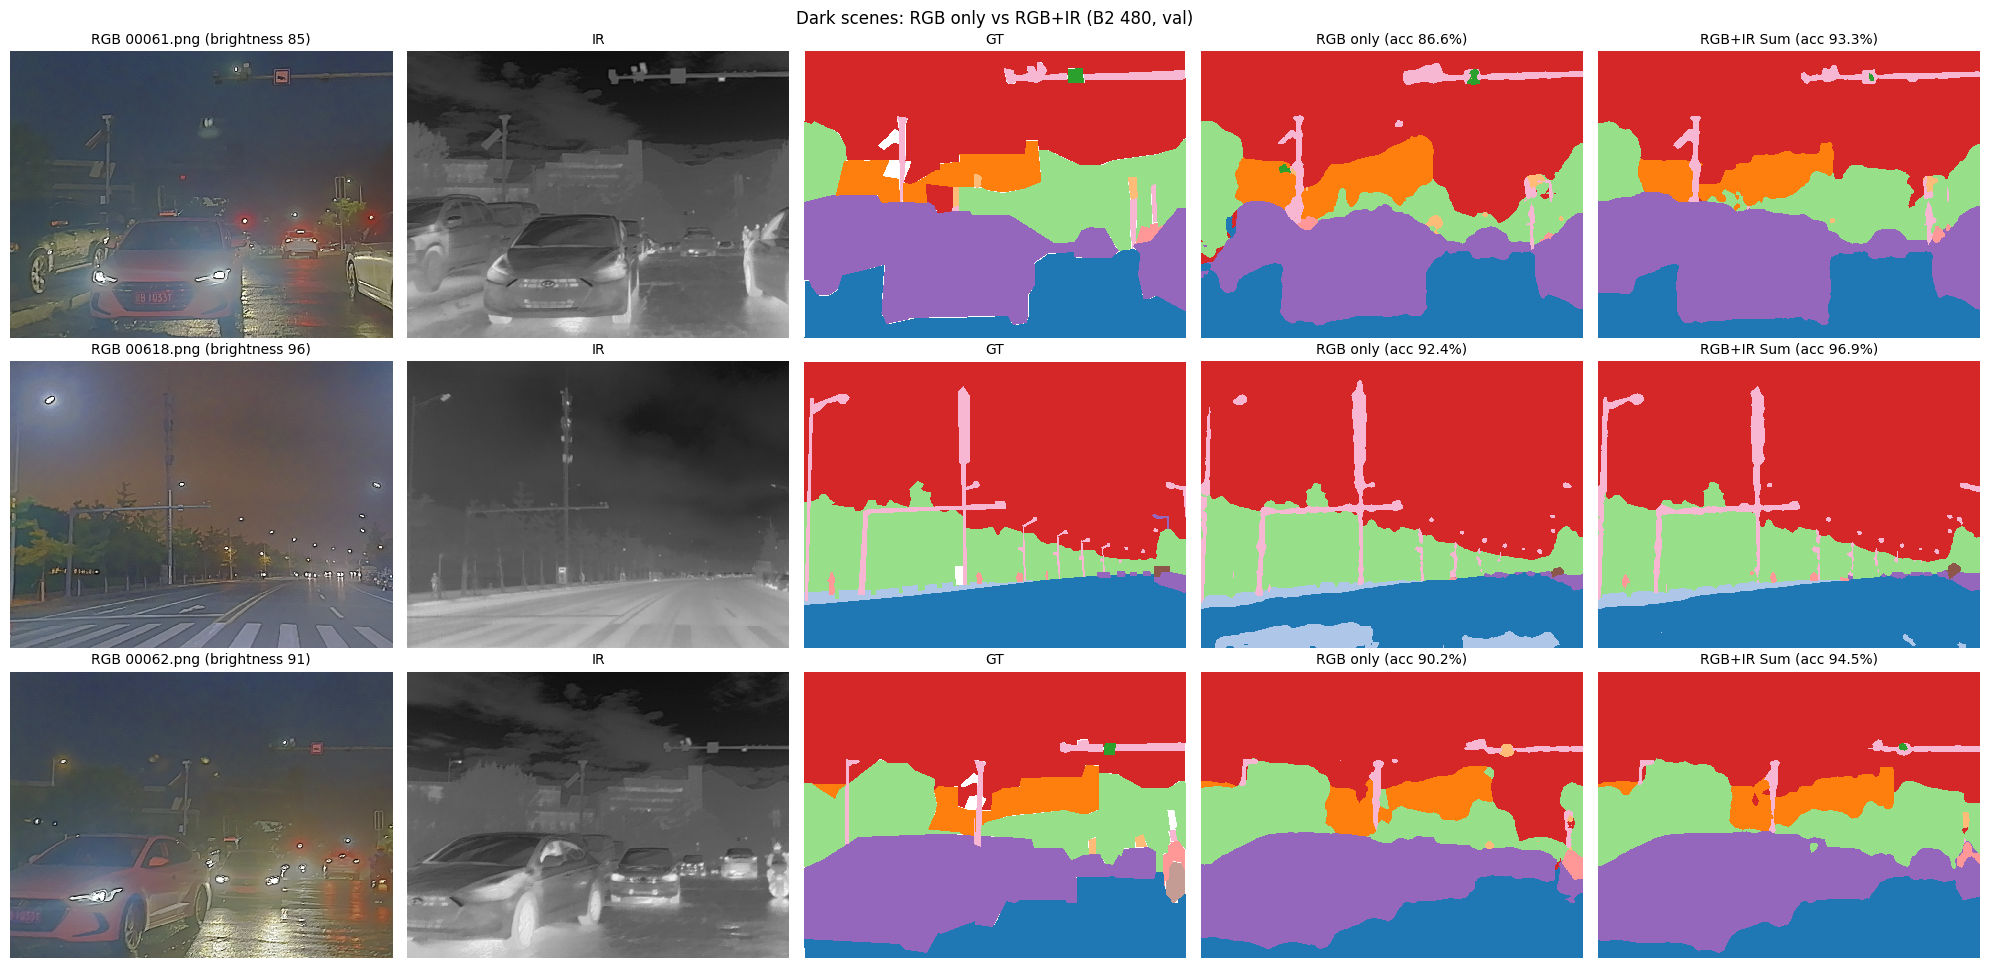

In [ ]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(plt.cm.tab20(np.linspace(0, 1, 20))[:NC])

def pixacc(cm): return np.diag(cm).sum() / max(cm.sum(), 1)

# 어두운 그룹에서 IR 덕분에 가장 많이 좋아진 3장
pick = sorted(groups["어두움"], key=lambda n: pixacc(cms["B2 Sum 480"][n]) - pixacc(cms["B2 RGB 480"][n]), reverse=True)[:3]
fig, axes = plt.subplots(len(pick), 5, figsize=(20, 3.3 * len(pick)))
for row, n in zip(np.atleast_2d(axes), pick):
    it = next(i for i in items if i["name"] == n)
    gt = load_gt(it).astype(float); gt[gt == IGN] = np.nan
    panels = [(Image.open(root / it["rgb"]), f"RGB {n} (brightness {bright[n]:.0f})"),
              (Image.open(root / it["aux"]), "IR"), (gt, "GT"),
              (np.array(Image.open(f"/content/val_b2_rgb_480/{n}")), f"RGB only (acc {100 * pixacc(cms['B2 RGB 480'][n]):.1f}%)"),
              (np.array(Image.open(f"/content/val_b2_sum_480/{n}")), f"RGB+IR Sum (acc {100 * pixacc(cms['B2 Sum 480'][n]):.1f}%)")]
    for ax, (img, t) in zip(row, panels):
        seg = t.startswith(("GT", "RGB only", "RGB+IR"))
        ax.imshow(img, cmap=cmap if seg else None, vmin=0, vmax=NC - 1, interpolation="nearest")
        ax.set_title(t, fontsize=10); ax.axis("off")
plt.suptitle("Dark scenes: RGB only vs RGB+IR (B2 480, val)")
plt.tight_layout(); plt.savefig(OUT / "dark_rgb_vs_sum.png", dpi=150); plt.show()

B2 Sum 480 val mIoU (재계산): 73.65   (로그 73.65)


,class_id,name,gt_pixels,B2_Sum_480,B2_Sum_384,480_minus_384
12,12,Bicycle,994,46.60,39.83,6.77
1,1,Sidewalk,2098203,57.04,57.03,0.01
13,13,Pole,1576838,60.72,57.29,3.43
3,3,TrafficLight,72676,63.10,61.78,1.32
11,11,Motorcycle,48405,64.15,63.13,1.02
9,9,Truck,353887,65.58,65.85,-0.27
7,7,Person,311999,67.16,65.14,2.02
10,10,Bus,287777,73.72,77.05,-3.33
4,4,TrafficSign,226116,76.24,75.57,0.67
8,8,Car,5477753,88.95,88.53,0.42


,class,IoU,오답1,오답2,오답3
0,12 Bicycle,46.60,Sky 15.5%,Sidewalk 14.7%,Road 9.3%
1,1 Sidewalk,57.04,Road 26.6%,Vegetation 3.8%,Car 1.0%
2,13 Pole,60.72,Vegetation 12.6%,Building 8.5%,Sky 5.8%
3,3 TrafficLight,63.10,Vegetation 10.4%,Building 8.5%,Pole 2.5%
4,11 Motorcycle,64.15,Car 14.0%,Person 5.2%,Bus 4.5%
5,9 Truck,65.58,Car 7.6%,Building 5.9%,Vegetation 5.4%


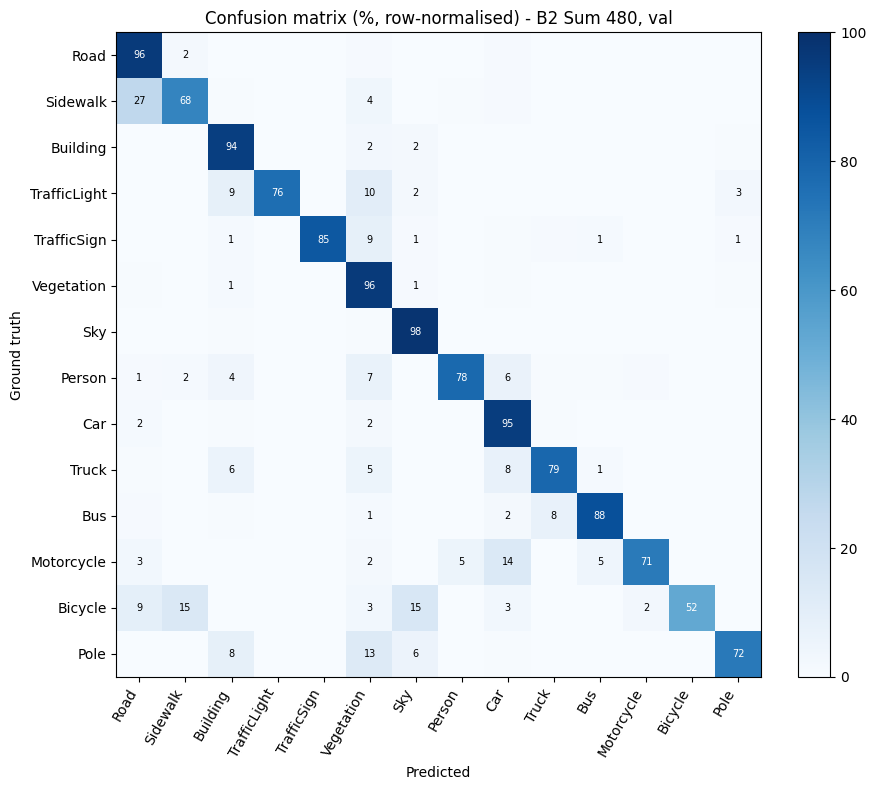

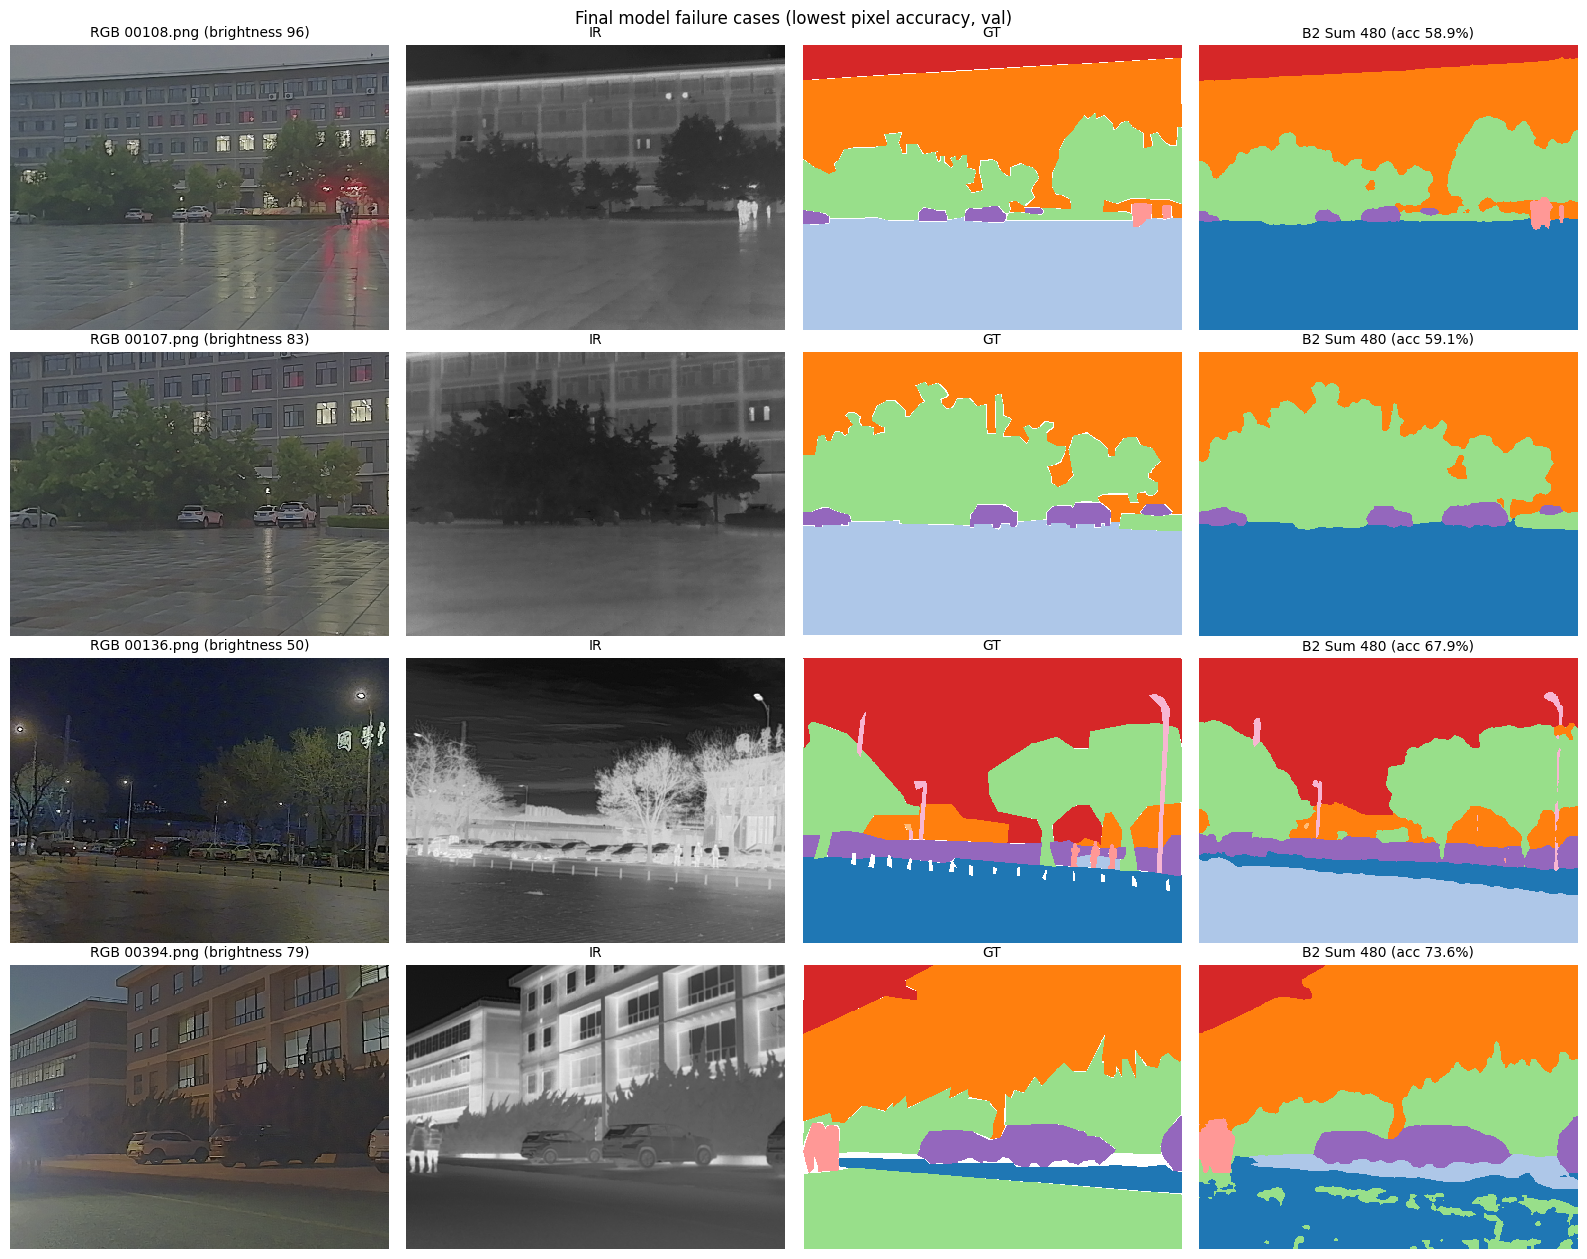

,image,pixel acc (%),top error,share of errors (%)
0,00108.png,58.9,Sidewalk -> Road,93.0
1,00107.png,59.1,Sidewalk -> Road,94.7
2,00136.png,67.9,Road -> Sidewalk,72.6
3,00394.png,73.6,Vegetation -> Road,78.9


In [ ]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image

OUT = Path("/content/drive/MyDrive/ICV_FMB/analysis"); OUT.mkdir(parents=True, exist_ok=True)
root = Path("/content/ICV-FMB-Fusion/data/FMB_prepared")
meta = json.loads((root / "meta.json").read_text())
items = json.loads((root / "index_val.json").read_text())
NC, IGN, SHIFT = meta["num_classes"], meta["ignore"], meta["label_shift"]
NAMES = ["Road", "Sidewalk", "Building", "TrafficLight", "TrafficSign", "Vegetation", "Sky",
         "Person", "Car", "Truck", "Bus", "Motorcycle", "Bicycle", "Pole"]
PRED = "/content/val_b2_sum_480"

def load_gt(it):
    gt = np.array(Image.open(root / it["label"])).astype(np.int64) - SHIFT
    gt[(gt < 0) | (gt >= NC)] = IGN
    return gt

# 1) 이미지별 / 전체 혼동행렬
per_img, cm = {}, np.zeros((NC, NC), np.int64)
for it in items:
    gt = load_gt(it); m = gt != IGN
    pr = np.array(Image.open(f"{PRED}/{it['name']}")).astype(np.int64)
    c = np.bincount(gt[m] * NC + pr[m], minlength=NC * NC).reshape(NC, NC)
    per_img[it["name"]] = c; cm += c
tp = np.diag(cm).astype(float)
iou = 100 * tp / np.maximum(cm.sum(0) + cm.sum(1) - tp, 1)
print(f"B2 Sum 480 val mIoU (재계산): {iou.mean():.2f}   (로그 73.65)")

# 2) 클래스별 IoU (+ 384 모델과 비교: 이전 분석 CSV가 있으면)
cls = pd.DataFrame({"class_id": range(NC), "name": NAMES, "gt_pixels": cm.sum(1), "B2_Sum_480": iou})
prev = Path("/content/drive/MyDrive/ICV_FMB/b2_class_iou.csv")
if prev.exists():
    p = pd.read_csv(prev)[["class_id", "B2_Sum"]].rename(columns={"B2_Sum": "B2_Sum_384"})
    cls = cls.merge(p, on="class_id"); cls["480_minus_384"] = cls["B2_Sum_480"] - cls["B2_Sum_384"]
display(cls.round(2).sort_values("B2_Sum_480"))
cls.round(4).to_csv(OUT / "final_class_iou_b2_480.csv", index=False)

# 3) IoU 낮은 6개 클래스의 주요 오답
rows = []
for c in np.argsort(iou)[:6]:
    r = cm[c].astype(float); total = r.sum(); r[c] = 0
    top = np.argsort(r)[::-1][:3]
    rows.append({"class": f"{c} {NAMES[c]}", "IoU": round(iou[c], 2),
                 **{f"오답{k+1}": f"{NAMES[t]} {100 * r[t] / max(total, 1):.1f}%" for k, t in enumerate(top)}})
conf = pd.DataFrame(rows); display(conf); conf.to_csv(OUT / "final_top_confusions_b2_480.csv", index=False)

# 4) 정규화 혼동행렬 그림 (행 = 정답, 행 합 = 100%)
norm = 100 * cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=100)
for i in range(NC):
    for j in range(NC):
        if norm[i, j] >= 1:
            ax.text(j, i, f"{norm[i, j]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if norm[i, j] > 50 else "black")
ax.set_xticks(range(NC), NAMES, rotation=60, ha="right"); ax.set_yticks(range(NC), NAMES)
ax.set(xlabel="Predicted", ylabel="Ground truth", title="Confusion matrix (%, row-normalised) - B2 Sum 480, val")
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(OUT / "final_confusion_matrix_b2_480.png", dpi=180); plt.show()

# 5) 실패 사례: 픽셀 정확도 낮은 4장
cmap = ListedColormap(plt.cm.tab20(np.linspace(0, 1, 20))[:NC])
acc = sorted((np.diag(c).sum() / max(c.sum(), 1), n) for n, c in per_img.items())
worst = [n for _, n in acc[:4]]
fig, axes = plt.subplots(len(worst), 4, figsize=(16, 3.2 * len(worst)))
for row, (a, n) in zip(axes, acc[:4]):
    it = next(i for i in items if i["name"] == n)
    gt = load_gt(it).astype(float); gt[gt == IGN] = np.nan
    bright = np.asarray(Image.open(root / it["rgb"]).convert("L"), dtype=np.float32).mean()
    panels = [(Image.open(root / it["rgb"]), f"RGB {n} (brightness {bright:.0f})"), (Image.open(root / it["aux"]), "IR"),
              (gt, "GT"), (np.array(Image.open(f"{PRED}/{n}")), f"B2 Sum 480 (acc {100 * a:.1f}%)")]
    for ax, (img, t) in zip(row, panels):
        seg = t.startswith(("GT", "B2"))
        ax.imshow(img, cmap=cmap if seg else None, vmin=0, vmax=NC - 1, interpolation="nearest")
        ax.set_title(t, fontsize=10); ax.axis("off")
plt.suptitle("Final model failure cases (lowest pixel accuracy, val)")
plt.tight_layout(); plt.savefig(OUT / "final_failure_cases_b2_480.png", dpi=150); plt.show()

# 6) 실패 4장에서 가장 많이 틀린 (정답 -> 예측) 조합
rows = []
for a, n in acc[:4]:
    c = per_img[n].copy(); np.fill_diagonal(c, 0)
    i, j = np.unravel_index(c.argmax(), c.shape)
    rows.append({"image": n, "pixel acc (%)": round(100 * a, 1), "top error": f"{NAMES[i]} -> {NAMES[j]}",
                 "share of errors (%)": round(100 * c[i, j] / max(c.sum(), 1), 1)})
fc = pd.DataFrame(rows); display(fc); fc.to_csv(OUT / "final_failure_cases_b2_480.csv", index=False)

Mounted at /content/drive


,실험,fusion,backbone,input,epochs,seed,target_fraction,best val mIoU,best epoch (1부터),기록된 epoch 수,best.pth
0,B0 RGB,rgb,mit-b0,384x512,30,0,-,61.53,29,30,True
1,B0 Sum,sum,mit-b0,384x512,30,0,-,65.48,30,30,True
2,B0 Sum+OS,sum,mit-b0,384x512,30,0,0.1,67.97,29,30,True
3,B0 Concat,concat,mit-b0,384x512,30,0,-,62.47,28,30,True
4,B0 Adaptive,adaptive,mit-b0,384x512,30,0,-,65.35,29,30,True
5,B0 Concat_res,concat_res,mit-b0,384x512,30,0,-,64.95,27,30,True
6,B0 Early,early,mit-b0,384x512,30,0,-,62.19,30,30,True
7,B2 Sum 384,sum,mit-b2,384x512,30,0,-,72.74,29,30,True
8,B2 Sum 480,sum,mit-b2,480x640,30,0,-,73.65,30,30,True
9,B2 RGB 480,rgb,mit-b2,480x640,30,0,-,70.99,30,30,True


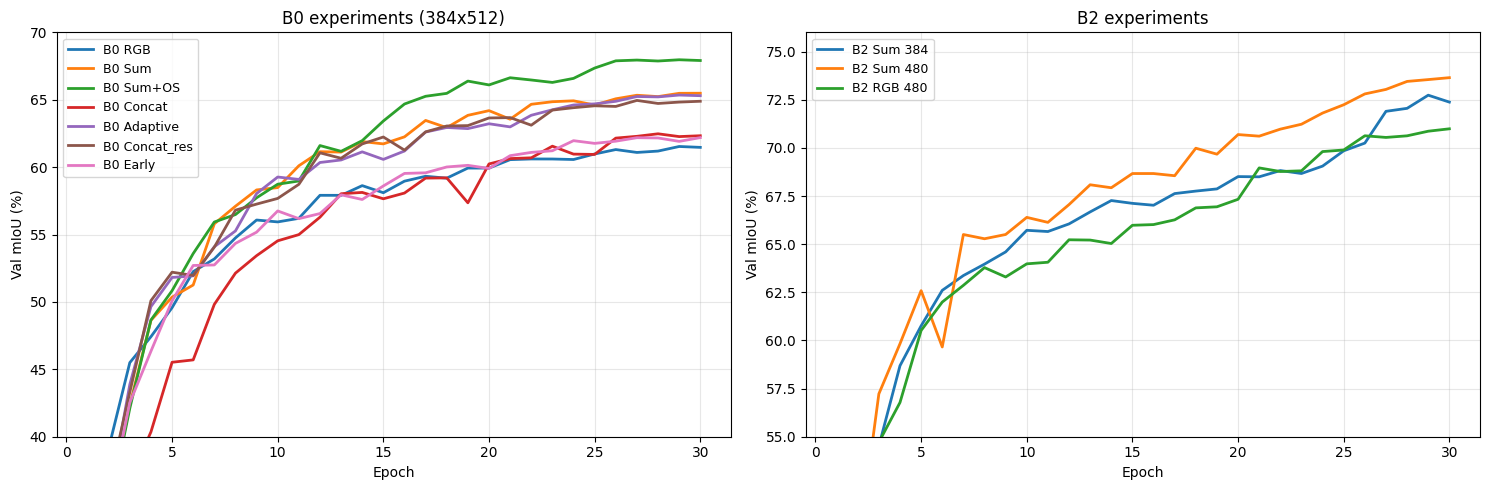

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RUNS = Path("/content/drive/MyDrive/ICV_FMB/runs")
OUT = Path("/content/drive/MyDrive/ICV_FMB/analysis"); OUT.mkdir(parents=True, exist_ok=True)
EXPS = [("B0 RGB", "fmb_rgb"), ("B0 Sum", "fmb_sum"), ("B0 Sum+OS", "fmb_sum_oversample10"),
        ("B0 Concat", "fmb_concat"), ("B0 Adaptive", "fmb_adaptive"), ("B0 Concat_res", "fmb_concat_res"),
        ("B0 Early", "fmb_early"), ("B2 Sum 384", "fmb_b2_sum"), ("B2 Sum 480", "fmb_b2_sum_480"),
        ("B2 RGB 480", "fmb_b2_rgb_480")]

rows, logs = [], {}
for label, folder in EXPS:
    d = RUNS / folder
    a = json.loads((d / "args.json").read_text())
    recs = [json.loads(l) for l in (d / "log.jsonl").read_text().splitlines() if l.strip()]
    logs[label] = recs
    best = max(recs, key=lambda r: r["val_mIoU"])
    rows.append({"실험": label, "fusion": a["fusion"], "backbone": a["backbone"].split("/")[-1],
                 "input": f'{a["height"]}x{a["width"]}', "epochs": a["epochs"], "seed": a["seed"],
                 "target_fraction": a.get("target_fraction", "-"),
                 "best val mIoU": round(best["val_mIoU"], 2), "best epoch (1부터)": best["epoch"] + 1,
                 "기록된 epoch 수": len(recs), "best.pth": (d / "best.pth").exists()})
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv(OUT / "run_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for label, recs in logs.items():
    ax = axes[1] if label.startswith("B2") else axes[0]
    ax.plot([r["epoch"] + 1 for r in recs], [r["val_mIoU"] for r in recs], label=label, lw=2)
axes[0].set(title="B0 experiments (384x512)", xlabel="Epoch", ylabel="Val mIoU (%)", ylim=(40, 70))
axes[1].set(title="B2 experiments", xlabel="Epoch", ylabel="Val mIoU (%)", ylim=(55, 76))
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "learning_curves.png", dpi=180); plt.show()

In [9]:
%cd /content/ICV-FMB-Fusion
import os
if not os.path.exists("/content/val_b2_sum_480"):
    !python predict.py --data_root data/FMB_prepared --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum_480/best.pth --split val --out /content/val_b2_sum_480
!python predict.py --data_root data/FMB_prepared --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum_480_oversample10/best.pth --split val --out /content/val_b2_sum_480_os

/content/ICV-FMB-Fusion
220 files -> /content/val_b2_sum_480_os.zip


In [ ]:
!ls /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum_480/

args.json  best.pth  last.pth  log.jsonl


In [ ]:
import os
if not os.path.exists("/content/ICV-FMB-Fusion"):
    !git clone https://github.com/suminilago/ICV-FMB-Fusion.git /content/ICV-FMB-Fusion
%cd /content/ICV-FMB-Fusion
%pip install -q -r requirements.txt
if not os.path.exists("data/FMB_prepared/meta.json"):
    !mkdir -p data/FMB_raw
    !cp /content/drive/MyDrive/ICV_FMB/data/train.zip /content/drive/MyDrive/ICV_FMB/data/test.zip data/FMB_raw/
    !cd data/FMB_raw && unzip -q -o train.zip && unzip -q -o test.zip
    !python tools/prepare_fmb.py --raw data/FMB_raw --out data/FMB_prepared

import json, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

RUNS = "/content/drive/MyDrive/ICV_FMB/runs"
for name, run in [("val_b2_sum_480", "fmb_b2_sum_480"), ("val_b2_sum_480_os", "fmb_b2_sum_480_oversample10")]:
    d = f"/content/{name}"
    if not os.path.exists(d + ".zip"):
        !python predict.py --data_root data/FMB_prepared --ckpt {RUNS}/{run}/best.pth --split val --out {d}
    if not list(Path(d).rglob("*.png")):
        zipfile.ZipFile(d + ".zip").extractall(d)

OUT = Path("/content/drive/MyDrive/ICV_FMB/analysis"); OUT.mkdir(parents=True, exist_ok=True)
root = Path("data/FMB_prepared")
meta = json.loads((root / "meta.json").read_text())
items = json.loads((root / "index_val.json").read_text())
NC, IGN, SHIFT = meta["num_classes"], meta["ignore"], meta["label_shift"]
NAMES = ["Road", "Sidewalk", "Building", "TrafficLight", "TrafficSign", "Vegetation", "Sky",
         "Person", "Car", "Truck", "Bus", "Motorcycle", "Bicycle", "Pole"]

def class_iou(d):
    png = {p.name: p for p in Path(d).rglob("*.png")}
    cm = np.zeros((NC, NC), np.int64)
    for it in items:
        gt = np.array(Image.open(root / it["label"])).astype(np.int64) - SHIFT
        gt[(gt < 0) | (gt >= NC)] = IGN
        pr = np.array(Image.open(png[it["name"]])).astype(np.int64)
        m = gt != IGN
        cm += np.bincount(gt[m] * NC + pr[m], minlength=NC * NC).reshape(NC, NC)
    tp = np.diag(cm).astype(float)
    return 100 * tp / np.maximum(cm.sum(0) + cm.sum(1) - tp, 1)

base = class_iou("/content/val_b2_sum_480")
os_ = class_iou("/content/val_b2_sum_480_os")
df = pd.DataFrame({"class": NAMES, "B2_Sum_480": base, "B2_Sum_480_OS": os_})
df["diff"] = df["B2_Sum_480_OS"] - df["B2_Sum_480"]
print(f"mIoU: {base.mean():.2f} -> {os_.mean():.2f}")
b = df.loc[df["class"] == "Bicycle", "diff"].item()
print(f"Bicycle 기여: {b / NC:+.2f}, 나머지 13개 기여: {(df['diff'].sum() - b) / NC:+.2f}")
display(df.round(2).sort_values("diff", ascending=False))
df.round(4).to_csv(OUT / "class_iou_b2_480_os_vs_sum.csv", index=False)

/content/ICV-FMB-Fusion
mIoU: 73.65 -> 74.46
Bicycle 기여: +1.14, 나머지 13개 기여: -0.33


,class,B2_Sum_480,B2_Sum_480_OS,diff
12,Bicycle,46.60,62.59,15.98
1,Sidewalk,57.04,57.61,0.57
10,Bus,73.72,74.25,0.53
0,Road,90.29,90.70,0.40
6,Sky,96.54,96.58,0.05
3,TrafficLight,63.10,63.11,0.00
5,Vegetation,91.12,91.12,-0.01
2,Building,89.83,89.74,-0.08
13,Pole,60.72,60.63,-0.08
8,Car,88.95,88.69,-0.26


In [10]:
%cd /content/ICV-FMB-Fusion

!python predict.py \
  --data_root data/FMB_prepared \
  --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum_480_oversample10/best.pth \
  --split test \
  --out /content/submission_b2_sum_480_os10

/content/ICV-FMB-Fusion
280 files -> /content/submission_b2_sum_480_os10.zip


In [13]:
from pathlib import Path

submission_zip = Path(
    "/content/submission_b2_sum_480_os10.zip"
)

checker = Path(
    "/content/drive/MyDrive/ICV_FMB/check_submission.py"
)

print("submission 존재:", submission_zip.exists())
print("검사 코드 존재:", checker.exists())

assert submission_zip.exists(), "submission.zip이 없습니다."
assert checker.exists(), "Drive에서 check_submission.py를 찾지 못했습니다."

submission 존재: True
검사 코드 존재: True


In [12]:
!cp /content/submission_b2_sum_480_os10.zip \
  /content/drive/MyDrive/ICV_FMB/submission_b2_sum_480_os10.zip

from google.colab import files

files.download(
    "/content/submission_b2_sum_480_os10.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
!cp /content/drive/MyDrive/ICV_FMB/check_submission.py .
!python check_submission.py --zip /content/submission_b2_sum_480_os10.zip --data_root data/FMB_prepared

OK: 280 files, names/sizes/class ids all valid (classes 0..13).


# 4. 리더보드 제출 (모델은 val mIoU로 선택)

## 4-1. B0 Adaptive

In [ ]:
%cd /content/ICV-FMB-Fusion
!python predict.py \
  --data_root /content/FMB_test_only \
  --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_adaptive/best.pth \
  --split test \
  --out /content/submission

/content/ICV-FMB-Fusion
280 files -> /content/submission.zip


## 4-2. B2 Sum 384x512

In [ ]:
%cd /content/ICV-FMB-Fusion
!python predict.py \
  --data_root data/FMB_prepared \
  --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum/best.pth \
  --split test \
  --out /content/submission_b2_sum

/content/ICV-FMB-Fusion
280 files -> /content/submission_b2_sum.zip


In [ ]:
!cp /content/drive/MyDrive/ICV_FMB/check_submission.py .
!python check_submission.py --zip /content/submission_b2_sum.zip --data_root data/FMB_prepared

!cp /content/submission_b2_sum.zip /content/drive/MyDrive/ICV_FMB/
!cp fusion_seg/fusion.py /content/drive/MyDrive/ICV_FMB/fusion_concat_res.py
from google.colab import files
files.download("/content/submission_b2_sum.zip")

OK: 280 files, names/sizes/class ids all valid (classes 0..13).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!python check_submission.py --zip /content/submission_b2_sum_480.zip --data_root data/FMB_prepared

OK: 280 files, names/sizes/class ids all valid (classes 0..13).


In [ ]:
%cd /content/ICV-FMB-Fusion
!python predict.py --data_root data/FMB_prepared --ckpt /content/drive/MyDrive/ICV_FMB/runs/fmb_b2_sum_480_oversample10/best.pth --split test --out /content/submission_b2_sum_480_os
!cp /content/drive/MyDrive/ICV_FMB/check_submission.py .
!python check_submission.py --zip /content/submission_b2_sum_480_os.zip --data_root data/FMB_prepared
!cp /content/submission_b2_sum_480_os.zip /content/drive/MyDrive/ICV_FMB/

/content/ICV-FMB-Fusion
280 files -> /content/submission_b2_sum_480_os.zip
cp: cannot stat '/content/drive/MyDrive/ICV_FMB/check_submission.py': No such file or directory
python3: can't open file '/content/ICV-FMB-Fusion/check_submission.py': [Errno 2] No such file or directory
